# Bonus B7: How to move retrieval to Pinecone

## Goal

We store and search the Chinook shop's policies and tickets in a managed vector database, then decide what changed by comparing it with local Chroma. We send **the same vectors** to both stores and ask the same ten labelled questions. The moment that teaches it is the staffing question: in both stores the file with the support hours ranks second, behind the file about representatives. A managed store does not change which file comes first. Managing the database and finding the right evidence are separate jobs.

## What you will learn

- How to embed the supplied files and keep each vector attached to its file name and metadata.
- How to create a uniquely named Pinecone index with its current raw Python SDK and read its readiness.
- How to upsert and search documents directly, reading IDs, cosine scores, text and metadata before using a helper.
- How to compare two stores on the same vectors with hit@1 and hit@3.
- How to narrow a search with metadata and keep datasets separate with namespaces.
- How to delete only the index this notebook created and verify it is gone.
- When a managed vector store is worth an account, compared with lab 10's local Chroma.

This is an **optional account lab**. Local Chroma is the open-source route in [Lab 10](../../10_Retrieval/README.md). This notebook restates every input and operation it needs; Lab 10 does not have to have run.

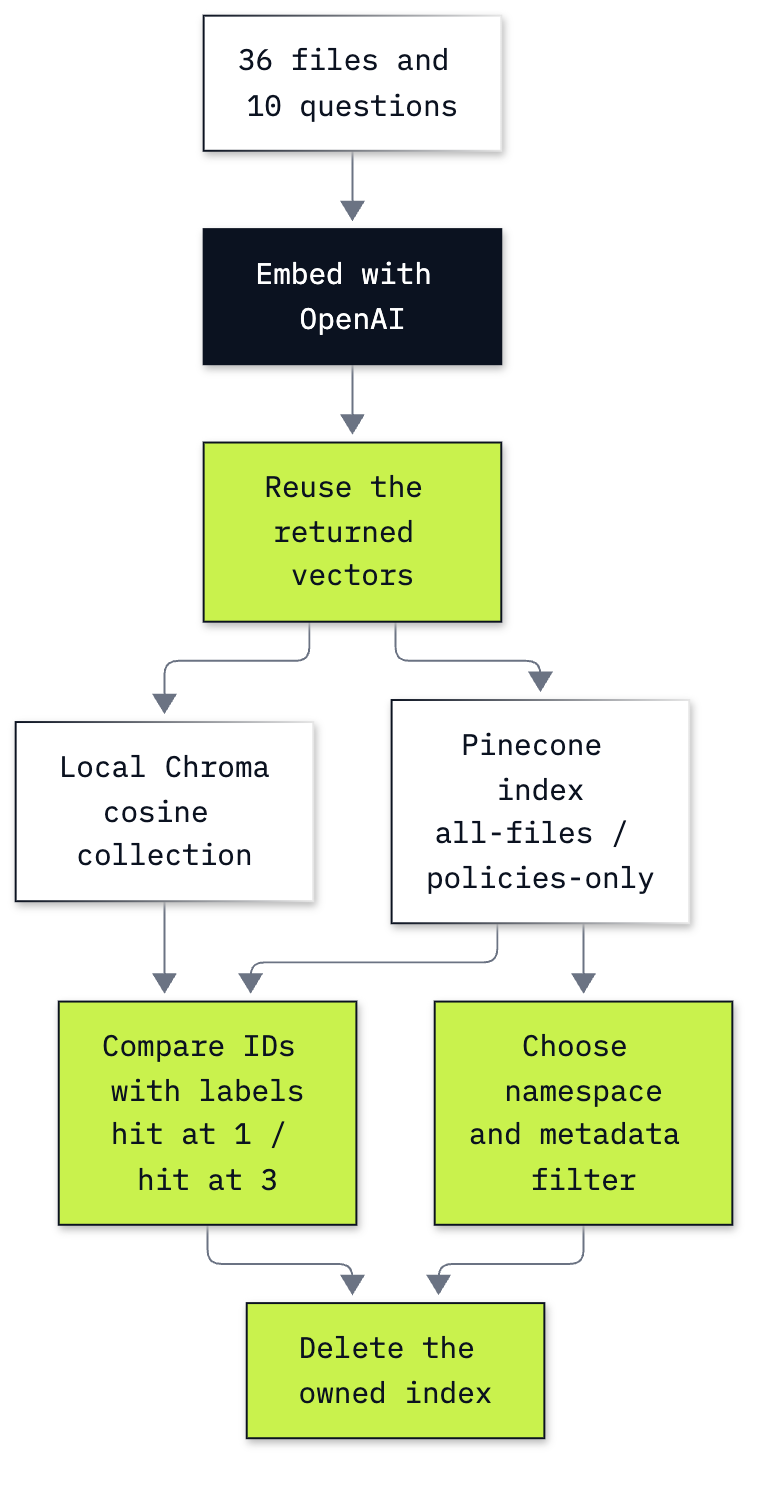

In [1]:
from IPython.display import Image

Image("resources/labB7_managed_store.png", width=760)

One batch call embeds the files and questions together; a separate one-question call first shows the embedding object. Both stores receive those returned lists of numbers; each store ranks them, and our code compares the IDs with an answer key. The diagram shows the ten labelled comparison questions; Part F adds one shipment question, giving 11 question rows in the batch. A namespace chooses which dataset a Pinecone request can see. Neither store generates an answer.

## Setup

Use the repository's environment (`uv sync --python 3.13` at its root) and select that environment as this notebook's kernel. Copy `.env.example` to `.env` at the repository root if needed. Set `OPENAI_API_KEY` and `PINECONE_API_KEY` there without sharing the file. For Pinecone, create an account at [the console](https://app.pinecone.io/), select your project, and create a project API key with permission to create/delete indexes and read/write documents.

Check your account's plan and usage in the console. [Pinecone pricing](https://www.pinecone.io/pricing/) lists (checked 5 November 2026) a Starter plan with included usage and AWS `us-east-1`. This lab uses that deployment and a tiny index. Availability, quotas and terms can change; if creation is refused, stop and inspect your quota. Keep existing indexes. No upgrade or purchase is needed for the teaching design.

⚠️ Running the cells sends the supplied teaching texts to OpenAI for embeddings and to Pinecone for storage/search. OpenAI embedding usage is billed separately from your Pinecone plan. We use external vectors, so Pinecone performs no embedding inference. Finish the **Clean up** cells even if you skip the challenge; if execution stops, use the saved index name in `outputs/ownership.json` to identify your own resource in the console.

The config cell finds the repository, loads the model settings and finds the OpenAI key without printing it; Lab 00 explains it line by line.

In [2]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


The second key is for the database service. We check presence only. The SDK client and the notebook's own outputs folder are next; `outputs/` is ignored by git.

In [3]:
import json
import time
import uuid
import numpy as np
from openai import OpenAI
from pinecone import Pinecone, DenseVectorQuery, RetryConfig

os.environ.setdefault("PINECONE_API_KEY", local.get("PINECONE_API_KEY") or "")
assert os.environ["PINECONE_API_KEY"], "Put PINECONE_API_KEY in .env at the repository folder."
client = OpenAI(timeout=30, max_retries=1)
pc = Pinecone(timeout=30, retry_config=RetryConfig(max_retries=1, max_wait=2))
LAB = ROOT / "bonus" / "B7_Pinecone_Retrieval"
OUTPUTS = LAB / "outputs"
OUTPUTS.mkdir(exist_ok=True)
EMBEDDING_MODEL = settings["EMBEDDING_MODEL"]
PRICE_EMBEDDING = float(settings["PRICE_EMBEDDING_PER_MILLION"])
embedding_tokens = 0
print("Pinecone key found: yes")
print("clients:", type(client).__name__, type(pc).__name__)

Pinecone key found: yes
clients: OpenAI Pinecone


## Part A: Keep the files, vectors and labels aligned

A search result must point back to the text that was embedded. We start with one real file, then build the three aligned lists that both stores will receive. The corpus is bundled: 20 policies and 16 support tickets, all teaching fixtures. Read it in place.

In [4]:
files = sorted((ROOT / "data" / "corpus").glob("*.md"))
names = [p.name for p in files]
texts = [p.read_text() for p in files]
metadatas = [{"kind": name.split("_")[0]} for name in names]
print("files:", len(files))
print("first id:", names[0], "| metadata:", metadatas[0])
print(texts[names.index("policy_returns.md")])

files: 36
first id: policy_accounts.md | metadata: {'kind': 'policy'}
# Returns

Physical items (CDs, vinyl, boxed sets) may be returned within 30 days of the invoice date if unopened.

Opened physical media can be returned within 14 days only if the disc is defective. A replacement is preferred over a refund.

Digital downloads and streamed albums cannot be returned. See policy_digital_downloads.md.

Start a return by writing to support. Include the invoice number. Support will reply within the SLA in policy_support_hours.md.



`policy_returns.md` answers the familiar question *How long do I have to return an unopened CD?*: 30 days from the invoice date. The `kind` label is the part before the first underscore, either `policy` or `ticket`; we will filter on it.

An **embedding** is a list of numbers representing a text for comparison with other texts. First use the public OpenAI client on that one question, before any batch or helper.

In [5]:
QUESTION = "How long do I have to return an unopened CD?"
response = client.embeddings.create(model=EMBEDDING_MODEL, input=QUESTION)
example_vector = response.data[0].embedding
embedding_tokens += response.usage.prompt_tokens
print(type(example_vector).__name__, "of", len(example_vector), "numbers")
print("first four:", [round(x, 4) for x in example_vector[:4]])
print("norm:", round(float(np.linalg.norm(example_vector)), 4))
print("tokens:", response.usage.prompt_tokens)

list of 1536 numbers
first four: [0.0074, 0.0726, 0.0195, 0.0014]
norm: 1.0
tokens: 12


`data[0].embedding` is the vector for our single input. Its norm is its geometric length, close to 1. No one position means “returns”; comparing the whole vector carries the meaning. We now embed every file and every test question together, then reuse these exact returned vectors in both stores.

The answer key below comes from reading the supplied files. Eight questions have a file that answers; two have none. These labels are for scoring after the search. They never become part of an embedding request. In particular, the phone question is answered by the final sentence of `policy_data_retention.md` (support is email only), and the second-disc question by `policy_shipping.md` (one parcel per invoice).

In [6]:
LABELLED = [
    ("How long do I have to return an unopened CD?", "policy_returns.md"),
    ("When is support staffed?", "policy_support_hours.md"),
    ("Do gift cards expire?", "policy_gift_cards.md"),
    ("How many business days does a refund take?", "policy_refunds.md"),
    ("My download link expired. Can I get a new one?", "policy_digital_downloads.md"),
    ("Can I pay with bitcoin?", "policy_payment.md"),
    ("Is there a phone number I can call for support?", "policy_data_retention.md"),
    ("Can you ship the second disc of my set separately?", "policy_shipping.md"),
    ("What is Chinook's revenue target for 2014?", None),
    ("What is the CEO's personal mobile number?", None),
]
SHIPPED = "When was the replacement for the warped vinyl shipped?"
questions = [question for question, _ in LABELLED] + [SHIPPED]
response = client.embeddings.create(model=EMBEDDING_MODEL, input=texts + questions)
all_vectors = [item.embedding for item in response.data]
vectors = all_vectors[:len(texts)]
question_vectors = dict(zip(questions, all_vectors[len(texts):]))
embedding_tokens += response.usage.prompt_tokens
q = question_vectors[QUESTION]
print("file matrix:", np.asarray(vectors).shape)
print("question matrix:", np.asarray(list(question_vectors.values())).shape)
print("answerable:", sum(label is not None for _, label in LABELLED), "| unanswerable: 2")
print("embedding tokens:", embedding_tokens)
print(f"embedding cost: ${embedding_tokens * PRICE_EMBEDDING / 1_000_000:.8f}")

file matrix: (36, 1536)
question matrix: (11, 1536)
answerable: 8 | unanswerable: 2
embedding tokens: 2666
embedding cost: $0.00005332


- **36 rows** in the file matrix: row `i` belongs to `names[i]`, `texts[i]` and `metadatas[i]`.
- **1,536 columns:** the numbers in each embedding.
- **11 question rows:** ten labelled questions plus the ticket-date question used to test namespace isolation. `zip` pairs each question with the vector at the same position.

⚠️ Keep all lists in this order. Sorting names after embedding would attach real vectors to the wrong text while preserving the matrix shape.

**Checkpoint A.** 36 × 1,536 file matrix, 11 × 1,536 question matrix; 2,666 input tokens in total so far, costing $0.00005332 at the configured price. The alignment makes it possible to compare stores without embedding differences.

## Part B: Create an index that belongs to this run

A managed database runs outside this process. Pinecone's **control plane** creates and describes the index; its **data plane** stores and searches documents inside it. We list the existing indexes before creating anything and remember their names, so cleanup can check they remain.

A random suffix gives each run a new name. We record the name before creating it, so a stopped notebook still leaves a way to find its own resource. If you rerun from the top after an interruption, first clean up the previous name; do not overwrite the ownership file while that index still exists.

In [7]:
existing_names = {item.name for item in pc.indexes.list()}
print("indexes present before this run:", len(existing_names))
ownership_file = OUTPUTS / "ownership.json"
if ownership_file.exists():
    previous = json.loads(ownership_file.read_text())["index_name"]
    assert previous not in existing_names, f"Clean up your previous index first: {previous}"
RUN_ID = uuid.uuid4().hex[:12]
INDEX_NAME = f"b7-chinook-{RUN_ID}"
assert INDEX_NAME not in existing_names
ownership_file.write_text(json.dumps({"index_name": INDEX_NAME, "run_id": RUN_ID}))
print("this run owns:", INDEX_NAME)

indexes present before this run: 0
this run owns: b7-chinook-adcf3b1535c1


The schema names one searchable field, `embedding`. Its dimension must match our returned vectors; `cosine` ranks by their angle, with higher scores nearer. On two unit vectors `[1, 0]` and `[0.8, 0.6]`, cosine is `1 × 0.8 + 0 × 0.6 = 0.8`. Identical directions score 1. A cosine is a similarity measure, never a probability that the file answers.

We supply a plain schema dictionary because it makes the stored field visible. `deployment` chooses managed AWS `us-east-1`. We request no dedicated nodes or integrated embedding model. The [current SDK](https://sdk.pinecone.io/python/getting-started/quickstart.html) uses `indexes.create` and `index.documents`; older `create_index(dimension=..., spec=...)` examples use a compatibility interface. `timeout=120` bounds the wait for readiness, and the client bounds each request and retry.

In [8]:
schema = {"fields": {"embedding": {
    "type": "dense_vector", "dimension": len(vectors[0]), "metric": "cosine"
}}}
print("schema:", schema)
info = pc.indexes.create(
    name=INDEX_NAME,
    schema=schema,
    deployment={"deployment_type": "managed", "cloud": "aws", "region": "us-east-1"},
    tags={"lab": "b7", "run": RUN_ID},
    deletion_protection="disabled",
    timeout=120,
)
info = pc.indexes.describe(INDEX_NAME)
print("index:", info.name)
print("status:", info.status.to_dict())
print("deployment:", type(info.deployment).__name__, info.deployment.cloud, info.deployment.region)
assert info.status.ready
index = pc.index(host=info.host)
print("data-plane object:", type(index).__name__)

schema: {'fields': {'embedding': {'type': 'dense_vector', 'dimension': 1536, 'metric': 'cosine'}}}


index: b7-chinook-adcf3b1535c1
status: {'ready': True, 'state': 'Ready'}
deployment: ManagedDeployment aws us-east-1
data-plane object: Index


`ready: True` means the index accepts requests. It says nothing about documents being searchable; we have not written any yet. The returned host directs our `Index` object to this specific database, while `pc.indexes` continues to manage its lifecycle.

**Checkpoint B.** One uniquely named index, tagged with this run's ID, ready on AWS `us-east-1`. Keep the printed name for cleanup; names that existed before this run are never used for writes or deletion.

## Part C: Upsert and search documents directly

We put the ID, vector and text into one Pinecone document before loading the collection. **Upsert** inserts a new ID or replaces the document with that ID in the chosen namespace. A **namespace** is a named partition inside the index. We use `all-files` first; every read must name that same partition.

Here is one document before the network call. `_id` is the reserved ID; `embedding` matches our schema; `text` carries the original file; `kind` carries the same metadata as Chroma. The `**metadatas[i]` expansion copies `kind` into the document beside its other fields. Only the vector field is declared for search. Other fields are stored as metadata, and `kind` can be filtered.

In [9]:
i = names.index("policy_returns.md")
first_document = {
    "_id": names[i], "embedding": vectors[i], "text": texts[i], **metadatas[i]
}
print("id:", first_document["_id"])
print("kind:", first_document["kind"])
print("text:", first_document["text"].splitlines()[0])
print("embedding:", len(first_document["embedding"]), "numbers")
NS = "all-files"
upsert_one = index.documents.upsert(namespace=NS, documents=[first_document])
print("upserted:", upsert_one.upserted_count)

id: policy_returns.md
kind: policy
text: # Returns
embedding: 1536 numbers


upserted: 1


The write accepted one document. Pinecone applies writes asynchronously: an acknowledgement does not guarantee that the next read sees it. We fetch that ID until it is visible, with a finite wait. `fetch` retrieves IDs directly; it performs no similarity ranking.

In [10]:
for attempt in range(60):
    fetched = index.documents.fetch(namespace=NS, ids=[names[i]], include_fields=["kind", "text"])
    if names[i] in fetched.documents:
        break
    time.sleep(1)
else:
    raise TimeoutError("The first document was not visible within the teaching wait; use Clean up.")
print(fetched.to_dict())

{'documents': {'policy_returns.md': {'_id': 'policy_returns.md', 'kind': 'policy', 'text': '# Returns\n\nPhysical items (CDs, vinyl, boxed sets) may be returned within 30 days of the invoice date if unopened.\n\nOpened physical media can be returned within 14 days only if the disc is defective. A replacement is preferred over a refund.\n\nDigital downloads and streamed albums cannot be returned. See policy_digital_downloads.md.\n\nStart a return by writing to support. Include the invoice number. Support will reply within the SLA in policy_support_hours.md.\n'}}, 'namespace': 'all-files', 'usage': {'read_units': 1}}


The `documents` dictionary is keyed by the requested file name. Its text is the returns policy we read; fetching it proves the write reached a readable record. We excluded the large vector from the response. Next we repeat the same document shape for all 36 files, using the vectors already in memory.

In [11]:
documents = []
for name, text, vector, metadata in zip(names, texts, vectors, metadatas):
    documents.append({"_id": name, "embedding": vector, "text": text, **metadata})
upsert_all = index.documents.upsert(namespace=NS, documents=documents)
print("upserted:", upsert_all.upserted_count)
for attempt in range(60):
    stats = index.describe_index_stats()
    count = stats.namespaces.get(NS)
    if count and count.vector_count == len(documents):
        break
    time.sleep(1)
else:
    raise TimeoutError("The corpus count did not reach 36; use Clean up.")
print("namespace counts:", {name: part.vector_count for name, part in stats.namespaces.items()})

upserted: 36


namespace counts: {'all-files': 36}


The first file was replaced, so the count is 36, rather than 37. This is a count check, not a relevance check. We now make one similarity search with the familiar returns question. `DenseVectorQuery` names the vector field and supplies the question's existing vector; it makes no embedding call.

In [12]:
got = index.documents.search(
    namespace=NS,
    score_by=[DenseVectorQuery(field="embedding", values=q)],
    top_k=3,
    include_fields=["kind", "text"],
)
print(type(got).__name__)
print(got.to_dict())

SearchDocumentsResponse
{'matches': [{'_id': 'policy_returns.md', '_score': 0.61327714, 'kind': 'policy', 'text': '# Returns\n\nPhysical items (CDs, vinyl, boxed sets) may be returned within 30 days of the invoice date if unopened.\n\nOpened physical media can be returned within 14 days only if the disc is defective. A replacement is preferred over a refund.\n\nDigital downloads and streamed albums cannot be returned. See policy_digital_downloads.md.\n\nStart a return by writing to support. Include the invoice number. Support will reply within the SLA in policy_support_hours.md.\n'}, {'_id': 'policy_warranty.md', '_score': 0.46400625, 'kind': 'policy', 'text': '# Warranty on physical media\n\nManufacturing defects are covered for 90 days from the invoice date. This is separate from the return window.\n\nWear from ordinary play (scratches, a warped sleeve from sunlight) is not a defect.\n\nWe do not warranty third-party players, needles, or headphones sold as add-ons after 30 days.\n'},

Read the raw object before extracting fields:

| Field | Meaning |
|---|---|
| `matches` | documents ordered by decreasing cosine similarity |
| each match's `_id` and `_score` | the file name and its similarity; in Python use `.id` and `.score` |
| `kind` and `text` | our stored metadata, returned because `include_fields` asked for them |
| `namespace` | the partition searched |
| `usage` | service usage units if the response reports them; these are separate from OpenAI tokens |

Here `usage.read_units` is 1 although three matches came back: it counts service usage, rather than result documents. A search without `include_fields` returns IDs and scores only. Our own field names appear directly on each match, such as `match.kind`. There is no Chroma-style list of lists because this request carries one query vector.

In [13]:
for match in got.matches:
    print(f"{match.score:.6f}  {match.id}  {match.kind}  {match.text.splitlines()[0]}")

0.613277  policy_returns.md  policy  # Returns
0.464006  policy_warranty.md  policy  # Warranty on physical media
0.429862  policy_damaged_media.md  policy  # Damaged media


`policy_returns.md` ranks first at cosine **0.613277**. Its text contains the 30-day unopened-item rule. The warranty and damaged-media files are nearby topics, but they do not replace that rule. A high similarity needs this text check before we treat a result as evidence.

From here on, a small helper repeats exactly this raw call. Its input is a vector, so comparing stores never embeds the question twice. It returns the same SDK result object; callers can still inspect `matches`, `namespace` and `usage`.

In [14]:
def search_pinecone(vector, k=3, metadata_filter=None, namespace=NS):
    return index.documents.search(
        namespace=namespace,
        score_by=[DenseVectorQuery(field="embedding", values=vector)],
        top_k=k,
        include_fields=["kind", "text"],
        filter=metadata_filter,
    )

print("helper IDs:", [match.id for match in search_pinecone(q).matches])

helper IDs: ['policy_returns.md', 'policy_warranty.md', 'policy_damaged_media.md']


**Checkpoint C.** A single write and fetch, then 36 records in `all-files`; the returns policy is first in the raw search and the helper. The score says how close its vector is to the question. Reading its text establishes that the first rule actually answers.

## Part D: Compare the same vectors in local Chroma

A change of database should be measured on the same inputs. We create an in-memory Chroma collection with **cosine** explicitly selected, rather than comparing Pinecone cosine with Chroma's default squared distance. Both stores receive our exact original lists; Chroma does no embedding.

In [15]:
import chromadb

chroma = chromadb.EphemeralClient()
collection = chroma.create_collection(
    f"b7-{RUN_ID}", configuration={"hnsw": {"space": "cosine"}}, embedding_function=None
)
collection.add(ids=names, documents=texts, embeddings=vectors, metadatas=metadatas)
local_got = collection.query(query_embeddings=[q], n_results=3, include=["distances", "metadatas"])
print("local count:", collection.count())
print(local_got)

local count: 36
{'ids': [['policy_returns.md', 'policy_warranty.md', 'policy_damaged_media.md']], 'embeddings': None, 'documents': None, 'uris': None, 'included': ['distances', 'metadatas'], 'data': None, 'metadatas': [[{'kind': 'policy'}, {'kind': 'policy'}, {'kind': 'policy'}]], 'distances': [[0.3867228627204895, 0.535994291305542, 0.5701383948326111]]}


`ids[0]`, `distances[0]` and `metadatas[0]` belong to our one question; the outer list supports a batch of questions. In Chroma's cosine space, **distance = 1 − cosine**. Pinecone returns cosine directly, so we convert the Chroma distance before comparing numbers. This conversion applies to the chosen cosine space. In Lab 10’s default squared-L2 space, cosine is `1 − squared_distance / 2` for these normalised embeddings.

In [16]:
print(f"{'Pinecone ID':37} {'cosine':>10} | {'Chroma ID':37} {'cosine':>10}")
for match, local_id, distance in zip(got.matches, local_got["ids"][0], local_got["distances"][0]):
    print(f"{match.id:37} {match.score:10.6f} | {local_id:37} {1-distance:10.6f}")

Pinecone ID                               cosine | Chroma ID                                 cosine
policy_returns.md                       0.613277 | policy_returns.md                       0.613277
policy_warranty.md                      0.464006 | policy_warranty.md                      0.464006
policy_damaged_media.md                 0.429862 | policy_damaged_media.md                 0.429862


The returns question has the same three file IDs in the same order, and the converted scores agree to the six decimals displayed here. This compares the files themselves; a close score for one file cannot be compared with the score for a different file just because they occupy the same position.

The comparison now needs the ten labels from Part A. **hit@k** is the fraction of the eight answerable questions whose labelled file appears in the top `k`. For example, if six right files appear in the first three results, hit@3 is `6 / 8 = 0.75`. Unanswerable questions have no right file, so we report their nearest files separately; including them in this denominator would mix retrieval coverage with abstention.

Carry the familiar returns question through first: does its right file appear at rank 1? The table repeats that check for each answerable question. Only the query vector goes to each store; the answer key stays in Python.

In [17]:
comparison = []
for question, label in LABELLED:
    vector = question_vectors[question]
    remote = search_pinecone(vector)
    local_result = collection.query(query_embeddings=[vector], n_results=3, include=["distances"])
    remote_ids = [match.id for match in remote.matches]
    local_ids = local_result["ids"][0]
    remote_rank = remote_ids.index(label) + 1 if label in remote_ids else None
    local_rank = local_ids.index(label) + 1 if label in local_ids else None
    local_scores = dict(zip(local_ids, [1 - d for d in local_result["distances"][0]]))
    gaps = [abs(match.score - local_scores[match.id])
            for match in remote.matches if match.id in local_scores]
    comparison.append({
        "question": question, "label": label,
        "pinecone_ids": remote_ids, "chroma_ids": local_ids,
        "pinecone_rank": remote_rank, "chroma_rank": local_rank,
        "same_order": remote_ids == local_ids,
        "max_shared_id_score_gap": max(gaps, default=0),
        "pinecone_scores": [(match.id, match.score) for match in remote.matches],
        "duplicate_ids": len(remote_ids) != len(set(remote_ids)),
        "pinecone_best": remote.matches[0].score,
    })

The loop prints nothing: for each of the ten questions it searches both stores with the same vector and keeps one dictionary in `comparison`. Its fields, in the order written:

| Field | What it holds | Used by |
|---|---|---|
| `question`, `label` | the question and its right file (`None` for the two unanswerable ones) | every check |
| `pinecone_ids`, `chroma_ids` | the three returned file IDs from each store, in rank order | the order check, the miss printout |
| `pinecone_rank`, `chroma_rank` | the right file's position, 1 to 3, or `None` when it is not in the top three | hit@1 and hit@3 |
| `same_order` | whether the two ordered ID lists are identical | the `same IDs` column |
| `max_shared_id_score_gap` | the largest score difference for a file both stores returned | the score comparison |
| `pinecone_scores` | each returned ID with its cosine | the miss printout |
| `duplicate_ids` | whether a Pinecone response repeated an ID | the repeated-ID count |
| `pinecone_best` | the top cosine | the unanswerable questions |

`remote_ids.index(label) + 1` turns a list position into a rank starting at 1; `local_scores` maps each Chroma ID to its cosine (`1 - distance`), so a gap is only computed for the same file. The next cell prints the rank table from these records.

In [17]:
print(f"{'question':53} {'Pinecone':>8} {'Chroma':>8} {'same IDs':>9}")
for row in comparison:
    if row["label"] is not None:
        print(f"{row['question']:53} {str(row['pinecone_rank'] or '-'):>8} "
              f"{str(row['chroma_rank'] or '-'):>8} {str(row['same_order']):>9}")

question                                              Pinecone   Chroma  same IDs
How long do I have to return an unopened CD?                 1        1      True
When is support staffed?                                     2        2      True
Do gift cards expire?                                        1        1      True
How many business days does a refund take?                   1        1      True
My download link expired. Can I get a new one?               2        2      True
Can I pay with bitcoin?                                      1        1      True
Is there a phone number I can call for support?              -        -      True
Can you ship the second disc of my set separately?           -        -      True


A rank of `-` means the labelled file was outside the first three. It still counts as a miss. Count the ranks now, then print the actual returned files for every miss so the metric stays connected to evidence.

In [18]:
answerable = [row for row in comparison if row["label"] is not None]
metrics = {}
for store in ["pinecone", "chroma"]:
    hit1 = sum(row[f"{store}_rank"] == 1 for row in answerable)
    hit3 = sum(row[f"{store}_rank"] is not None for row in answerable)
    metrics[store] = {"hit1": hit1, "hit3": hit3, "n": len(answerable)}
    print(f"{store:9} hit@1 {hit1}/8 = {hit1/8:.3f} | hit@3 {hit3}/8 = {hit3/8:.3f}")
print("identical top-three order:", sum(row["same_order"] for row in comparison), "/ 10")
print("largest score gap for a shared ID:", f"{max(row['max_shared_id_score_gap'] for row in comparison):.8f}")
print("responses with repeated IDs:", sum(row["duplicate_ids"] for row in comparison))
for row in answerable:
    if row["pinecone_rank"] != 1 or row["chroma_rank"] != 1:
        print("\n", row["question"], "| right file:", row["label"])
        print("Pinecone IDs and cosines:", row["pinecone_scores"])
        print("Chroma:  ", row["chroma_ids"])

pinecone  hit@1 4/8 = 0.500 | hit@3 6/8 = 0.750
chroma    hit@1 4/8 = 0.500 | hit@3 6/8 = 0.750
identical top-three order: 10 / 10
largest score gap for a shared ID: 0.00000082
responses with repeated IDs: 0

 When is support staffed? | right file: policy_support_hours.md
Pinecone IDs and cosines: [('policy_support_reps.md', 0.5277094), ('policy_support_hours.md', 0.47237673), ('policy_escalations.md', 0.38930303)]
Chroma:   ['policy_support_reps.md', 'policy_support_hours.md', 'policy_escalations.md']

 My download link expired. Can I get a new one? | right file: policy_digital_downloads.md
Pinecone IDs and cosines: [('ticket_02_puja_download_expired.md', 0.54526764), ('policy_digital_downloads.md', 0.5044245), ('policy_damaged_media.md', 0.2544732)]
Chroma:   ['ticket_02_puja_download_expired.md', 'policy_digital_downloads.md', 'policy_damaged_media.md']

 Is there a phone number I can call for support? | right file: policy_data_retention.md
Pinecone IDs and cosines: [('policy_suppor

When result orders differ, repeat the identical query three times below. The request keeps its vector, namespace and candidate set. This separates a one-response observation from a repeatable difference; every returned ID is kept as received.

In [19]:
differing_rows = [row for row in comparison if not row["same_order"]]
if not differing_rows:
    print("No differing orders to inspect in this run.")
for row in differing_rows:
    print(row["question"])
    for repeat in range(1, 4):
        again = search_pinecone(question_vectors[row["question"]])
        ids = [match.id for match in again.matches]
        print(repeat, [(match.id, round(match.score, 8)) for match in again.matches],
              "unique IDs:", len(ids) == len(set(ids)))

No differing orders to inspect in this run.


Both stores have **hit@1 = 4 / 8 = 0.500** and **hit@3 = 6 / 8 = 0.750**. The ten top-three lists have identical order in this saved run. The largest score gap for a shared ID is **0.00000082**, with no repeated IDs in those ten responses. The repeat cell therefore has no differing order to inspect.

The staffing question puts `policy_support_reps.md` before `policy_support_hours.md`: the right file is second in both stores. The download policy is also second, behind Puja’s expired-download ticket. The phone and second-disc questions miss their labelled files even at three results. Reading those files supplied the answer key; the search returned related topics instead. The `same IDs` column checks the complete ordered lists, rather than only set membership.

A score gap is computed only for the same ID present in both result lists. Pairing results by position would compare different files when the order differs. Repeated IDs, if a response contains them, are printed unchanged and flagged; they use a result slot and can alter the rank. We do not silently remove them.

Those are retrieval failures. A generator would need to read the returned evidence and say when it cannot answer. Changing the storage service cannot make a missing rule appear in its prompt.

The two questions with no answer still have nearest files:

In [20]:
for row in comparison:
    if row["label"] is None:
        print(row["question"])
        print(f"  best cosine {row['pinecone_best']:.6f} | {row['pinecone_ids']}")

What is Chinook's revenue target for 2014?
  best cosine 0.251348 | ['ticket_04_canada_free_shipping.md', 'ticket_16_overpayment_note.md', 'ticket_10_chile_student_discount.md']
What is the CEO's personal mobile number?
  best cosine 0.303620 | ['policy_escalations.md', 'policy_support_reps.md', 'policy_privacy.md']


The revenue-target question still gets a best cosine of **0.251348**; the CEO-mobile question gets **0.303620**. These are similarities to available text, not evidence that either answer exists. The labelled set is small and deliberately contains difficult questions; it illustrates a comparison method, rather than proving a store's general recall, capacity or latency. Approximate indexes can differ, and tied scores can change order; inspect IDs and full precision before attributing a small difference to meaning.

**Checkpoint D.** Both stores: hit@1 4/8 and hit@3 6/8; identical ordered lists for 10/10 questions, largest shared-ID score gap 0.00000082. The staffing rule remains second, while two answerable questions miss at three results. No new embedding call occurs in the comparison loop. The managed service changes where the records live and who operates storage; this experiment measures whether its rankings changed.

## Part E: Restrict the search with metadata

A ticket can repeat a rule and rank ahead of the policy. A metadata filter selects which documents compete for the nearest places. Predict the download question: will removing tickets let the policy come first?

We use the raw API again for the new argument. `filter={"kind": {"$eq": "policy"}}` allows only records with that metadata value. This changes the candidate set; it neither rewrites vectors nor makes a file more similar.

In [21]:
DOWNLOAD = "My download link expired. Can I get a new one?"
q_download = question_vectors[DOWNLOAD]
filtered = index.documents.search(
    namespace=NS, score_by=[DenseVectorQuery(field="embedding", values=q_download)],
    top_k=3, include_fields=["kind", "text"], filter={"kind": {"$eq": "policy"}},
)
unfiltered = search_pinecone(q_download)
for title, result in [("all files", unfiltered), ("policies only", filtered)]:
    print(title)
    for match in result.matches:
        print(f"  {match.score:.6f} {match.id} | {match.kind}")
assert all(match.kind == "policy" for match in filtered.matches)

all files
  0.545268 ticket_02_puja_download_expired.md | ticket
  0.504425 policy_digital_downloads.md | policy
  0.254473 policy_damaged_media.md | policy
policies only
  0.504425 policy_digital_downloads.md | policy
  0.254473 policy_damaged_media.md | policy
  0.242795 policy_returns.md | policy


The unfiltered search puts `ticket_02_puja_download_expired.md` first. Restricting candidates to policies puts `policy_digital_downloads.md` first at **0.504425**, the same displayed cosine it had before filtering. The policy moved because the higher-scoring ticket was excluded, not because its vector changed.

**Checkpoint E.** All filtered results have `kind = policy`, and the downloads policy retains its cosine score. That check establishes that tickets were excluded. It cannot establish that a policies-only search is appropriate for every question; a ticket's shipment date would be excluded too.

## Part F: Separate datasets with namespaces

A filter chooses records inside a partition. A namespace chooses the partition itself. We copy the already embedded 20 policies into `policies-only`, leaving `all-files` unchanged. The same file ID may exist in both namespaces; upserting one does not replace the other.

In [22]:
policy_documents = [doc for doc in documents if doc["kind"] == "policy"]
policy_write = index.documents.upsert(namespace="policies-only", documents=policy_documents)
print("upserted into policies-only:", policy_write.upserted_count)
for attempt in range(60):
    stats = index.describe_index_stats()
    part = stats.namespaces.get("policies-only")
    if part and part.vector_count == len(policy_documents):
        break
    time.sleep(1)
else:
    raise TimeoutError("The policy namespace did not reach 20; use Clean up.")
print("namespace counts:", {name: part.vector_count for name, part in stats.namespaces.items()})

upserted into policies-only: 20
namespace counts: {'policies-only': 20, 'all-files': 36}


There are 36 records in `all-files` and 20 in `policies-only`, 56 stored copies across this index. Copying records incurs service writes/storage even though we reuse vectors without a new embedding charge. This is a small illustration; separate namespaces often hold different customers or versions rather than copies.

Search the same download vector in both partitions, and compare the policies-only namespace with the filtered search above.

In [23]:
namespace_hits = search_pinecone(q_download, namespace="policies-only")
print("namespace:", namespace_hits.namespace)
print("namespace IDs:", [match.id for match in namespace_hits.matches])
print("filter IDs:   ", [match.id for match in filtered.matches])
print("same IDs:", [match.id for match in namespace_hits.matches] == [match.id for match in filtered.matches])

namespace: policies-only
namespace IDs: ['policy_digital_downloads.md', 'policy_damaged_media.md', 'policy_returns.md']
filter IDs:    ['policy_digital_downloads.md', 'policy_damaged_media.md', 'policy_returns.md']
same IDs: True


The `policies-only` search returns `policy_digital_downloads.md`, `policy_damaged_media.md` and `policy_returns.md`, in the same order as the metadata filter. Both searches see the same 20 policy records for this question, although one selects a partition and the other selects metadata within a larger partition.

Now a question only a ticket answers: ticket 06 says the replacement shipped **2012-07-20**. Ask both namespaces, still using the same question vector.

In [24]:
shipment_results = {}
for namespace in [NS, "policies-only"]:
    result = search_pinecone(question_vectors[SHIPPED], namespace=namespace)
    shipment_results[namespace] = [match.id for match in result.matches]
    print(namespace, shipment_results[namespace])
print("right ticket in all-files:", "ticket_06_germany_warped_vinyl.md" in shipment_results[NS])
print("right ticket in policies-only:", "ticket_06_germany_warped_vinyl.md" in shipment_results["policies-only"])

all-files ['ticket_06_germany_warped_vinyl.md', 'ticket_06_germany_warped_vinyl.md', 'policy_damaged_media.md']
policies-only ['policy_damaged_media.md', 'policy_warranty.md', 'policy_returns.md']
right ticket in all-files: True
right ticket in policies-only: False


The `all-files` response includes `ticket_06_germany_warped_vinyl.md`; `policies-only` cannot return it. Notice that the raw `all-files` list prints ticket 06 twice. We keep that SDK response as received: two returned slots carrying one ID are not two stored tickets (we wrote 36 records), and this run cannot tell whether the repeat came from the service or the SDK. What matters here is that the right ticket appears only in the partition that holds tickets. Each request searches only the named namespace. A successful request to the wrong partition can return plausible files while excluding the answer.

A namespace is a data partition, not proof that a caller was authorised to choose it. An application must derive the permitted namespace and filters from authenticated identity. Never treat a namespace argument supplied by the user or model as an access-control decision.

**Checkpoint F.** Namespace counts 36 and 20; the policies-only namespace agrees with the metadata filter on the download question; ticket 06 is available only in `all-files`. The separation changes what can be found, not the meaning of its vectors.

## When to use it

The core path stores the same corpus locally in Chroma, in lab 10, and needs only the OpenAI key. This lab's measurement says what moving to a managed store changes and what it does not. With the same vectors, both stores scored hit@1 4/8 and hit@3 6/8, returned identical ordered top-three lists for 10 of 10 questions, and the staffing rule stayed second in both. So Pinecone did not change relevance; fixing that is retrieval work (labs 10 and 11), whichever store holds the vectors. What it changed is who runs the database, and what we had to do in return: an account, an index whose readiness we waited for, writes we polled until they were visible, and a cleanup that deletes exactly the index this run created. Choose a managed store such as Pinecone when the corpus or traffic outgrows one machine, several services must search one shared index, or each customer needs its own partition and you would rather not operate the database yourselves. For a corpus the size of this desk, lab 10's Chroma is enough.

## What you can do now

- Keep source file IDs, text, metadata and embeddings aligned across stores.
- Create and inspect a managed index through its control plane, then search through its data-plane client.
- Read raw upsert, fetch and search objects before wrapping the repeated search call.
- Measure hit@1 and hit@3 using the same vectors and labels in two stores.
- Choose a metadata filter or a namespace and recognise when either hides the needed evidence.
- Identify the resource owned by one run and verify its deletion.

## Challenge

Do this before the cleanup cells below.

1. Search the shipment-date question in `all-files` with a **tickets-only filter**, then in `policies-only` with the same filter. Print each result's IDs and `kind` fields. The first can find ticket 06; the second has no tickets to return. Explain why relaxing `top_k` cannot restore a document excluded by the namespace.
2. Compare the download question's top three policy IDs in local Chroma (`where={"kind": "policy"}`) with the Pinecone filter and the `policies-only` namespace. Reuse `q_download`; make no embedding call. Read any order difference before deciding whether relevance changed.

**Expected outcome.** The shipment search in `all-files` returns only tickets and includes ticket 06; the same filter in `policies-only` returns zero matches. The three ways to select policies return the same download IDs in the saved worked solution. The full worked notebook in `solved/B7_pinecone_retrieval_solution.ipynb` includes its own setup, cloud run and cleanup.

In [25]:
# Your work: call search_pinecone with the tickets-only filter in both namespaces.
# Then use collection.query with q_download and a policies-only where argument.

## Clean up

Deleting the notebook or restarting its kernel does not delete a managed index. We delete exactly the saved name after checking its ownership tag. No existing index is selected by position, guessed from its contents, or deleted to make room.

If execution stopped earlier and the kernel still holds its variables, run this section before starting a new run. If you restarted the kernel, use the Pinecone console to locate the exact name saved in `outputs/ownership.json`, check its `run` tag against the saved run ID, and delete only that resource. Then restart this notebook from the top. The cells below use this live run’s variables; do not run Part B again while its previous index exists.

In [26]:
owned = json.loads(ownership_file.read_text())
owned_name = owned["index_name"]
assert owned_name.startswith("b7-chinook-")
if pc.indexes.exists(owned_name):
    owned_info = pc.indexes.describe(owned_name)
    assert owned_info.tags.get("run") == owned["run_id"], "Ownership tag differs; stop and inspect."
    pc.indexes.delete(owned_name, timeout=120)
after_names = {item.name for item in pc.indexes.list()}
assert owned_name not in after_names
assert existing_names <= after_names, "An index that existed before this run is now absent; inspect the console."
print("deleted and absent:", owned_name)
print("pre-existing index names still present:", existing_names <= after_names)
index.close()
pc.close()
print("clients closed")

deleted and absent: b7-chinook-adcf3b1535c1
pre-existing index names still present: True
clients closed


**Cleanup checkpoint.** The owned name is absent, every pre-existing name remains present, and the clients are closed. The preservation check concerns names; we never issued a data request to those other indexes. Pinecone's console is where you confirm account-wide usage and any plan charges. Deletion ends this index's stored data; it does not undo usage already billed.

The remaining local `outputs/ownership.json` only records the non-secret index name and run ID. It lets you identify an interrupted run and can be removed after confirming cleanup.

## Resources

- [Pinecone Python quickstart](https://sdk.pinecone.io/python/getting-started/quickstart.html): the current raw SDK lifecycle.
- [Pinecone schema and upsert](https://sdk.pinecone.io/python/how-to/documents/schema-and-upsert.html): searchable vector fields and document records.
- [Pinecone document search](https://sdk.pinecone.io/python/how-to/documents/search.html): `DenseVectorQuery`, returned fields and metadata filters.
- [Pinecone namespaces](https://sdk.pinecone.io/python/how-to/vectors/namespaces.html): partitions and namespace counts. Its vector examples use the older vector interface; this lab uses the same partition concept with document requests.
- [Pinecone pricing](https://www.pinecone.io/pricing/): plans, included usage and charges. Check your own account before creating resources.
- [Pinecone v10 migration](https://sdk.pinecone.io/python/migration/v10-migration.html): schema/document APIs and compatibility calls.
- [OpenAI embeddings](https://developers.openai.com/api/docs/guides/embeddings): vectors and embedding usage.
- [Chroma collection configuration](https://docs.trychroma.com/docs/collections/configure): choosing cosine rather than default squared distance.
- [Chroma metadata filters](https://docs.trychroma.com/docs/querying-collections/metadata-filtering): the local `where` argument.

Back to [the bonus lab list](../README.md) or [the full lab list](../../README.md).